# 实验 C　用共识聚类加权借鉴其他产品的召回历史

**研究问题**　同一批历史召回经过重抽样后，产品类别之间的同簇关系有多稳定？用这种稳定性分配参考权重，能否比实验 B 的一次 K-means 更准确地提示危险？

先运行 [DataPreprocessing.ipynb](DataPreprocessing.ipynb) 导出 `preprocessing_output/project_input_records.json`，再从项目目录运行本 Notebook。可以在下一格修改 `DATA_PATH`。环境需要 NumPy、pandas、scikit-learn、threadpoolctl 和 Matplotlib。

沿用 [项目大纲](PROJECT_OUTLINE.md) 的 11 个产品大类、2000–2018 年建模期和 2019–2024 年回测期。单位是「召回编号 × 产品大类」。在共同样本上复算 A 的本类危险比例和 B 的同簇借鉴，C 只替换外部参考权重。

In [1]:
from collections import Counter, defaultdict
from fractions import Fraction
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits


DATA_PATH = Path("preprocessing_output/project_input_records.json")
FAILURE_MODES = ("过热", "电气短路或电弧", "破裂或断裂", "松脱或分离", "泄漏", "意外启动")
CATEGORY_NAMES = {
    "BABY_PRODUCTS": "婴幼儿用品", "CLOTHING_ACCESSORIES": "服装及配饰",
    "ELECTRICAL": "电气产品", "FURNITURE": "家具", "HOME_APPLIANCES": "家用设备",
    "OTHER": "其他产品", "OUTDOOR_EQUIPMENT": "户外设备", "SPORTS_RECREATION": "运动休闲",
    "TOOLS_HARDWARE": "工具及五金", "TOYS_CHILDREN": "玩具及儿童用品", "TRANSPORTATION": "交通运输",
}
HAZARD_NAMES = {
    "BURN": "灼伤", "CHOKING": "窒息或噎塞", "CRASH": "碰撞事故", "CUTS": "割伤",
    "FALLING": "跌落", "FIRE": "火灾", "HEAT_RELATED_EXPOLOSION": "热相关爆炸",
    "HEAT_RELATED_EXPLOSION": "热相关爆炸", "IMPACT": "撞击伤害", "OTHER": "其他危险",
    "POISONING": "中毒", "SAFETY_EQUIPMENT_MALFUNCTION": "安全装备失灵",
}

if not DATA_PATH.is_file():
    raise FileNotFoundError("请运行 DataPreprocessing.ipynb，或指定导出的 project_input_records.json。")
rows = json.loads(DATA_PATH.read_text(encoding="utf-8"))
required_fields = {"recall_number", "recall_year", "product_classification",
                   "hazard_classification", "failure_modes"}
if not isinstance(rows, list) or not rows or any(
    not isinstance(row, dict) or not required_fields.issubset(row) for row in rows
):
    raise ValueError("数据缺少交接字段，请使用预处理导出的 project_input_records.json。")

cases = {}
years = {}
for row in rows:
    recall_id, year = row["recall_number"], row["recall_year"]
    if not isinstance(year, int) or not 2000 <= year <= 2024:
        raise ValueError(f"编号 {recall_id} 的年份不在项目范围内。")
    if years.setdefault(recall_id, year) != year:
        raise ValueError(f"编号 {recall_id} 对应不同年份，请复核原始记录。")
    if not row["product_classification"] or not row["hazard_classification"]:
        raise ValueError(f"编号 {recall_id} 缺少产品类别或危险标签。")
    for category in row["product_classification"]:
        case = cases.setdefault((recall_id, category), {
            "id": recall_id, "category": category, "year": year, "hazards": set(), "modes": set(),
        })
        case["hazards"].update(row["hazard_classification"])
        case["modes"].update(row["failure_modes"])

history, evaluation = [], []
for key in sorted(cases):
    case = cases[key]
    (history if case["year"] <= 2018 else evaluation).append(case)
assert {case["id"] for case in history}.isdisjoint(case["id"] for case in evaluation)

history_by_category = defaultdict(list)
for case in history:
    history_by_category[case["category"]].append(case)
categories = sorted(history_by_category)
hazards = sorted(set().union(*(case["hazards"] for case in history)))
if set(categories) != set(CATEGORY_NAMES) or {case["category"] for case in evaluation} != set(categories):
    raise ValueError("建模期和回测期均应覆盖项目的 11 个产品大类。")
if set(hazards) != set().union(*(case["hazards"] for case in evaluation)):
    raise ValueError("建模期和回测期的危险标签集合不同，请检查交接数据。")
print(f"建模期 {len(history):,} 个组合，回测期 {len(evaluation):,} 个组合。")

建模期 5,016 个组合，回测期 1,491 个组合。


## 1　用重抽样检查 B 的同簇关系

B 对每个大类计算六项失效比例，分母是本类至少识别到一种失效的历史组合，随后在完整的 11 × 6 矩阵上运行一次 K-means。C 在每个大类内对这些组合**按原样本量有放回抽样**，保留同一组合上的多种失效，再重算六项比例。每轮都用 B 的 3 簇设置，重复 200 轮。所有类别每轮都参与，因此一对类别的共识值就是同簇次数除以 200。

这里借鉴 Monti 等人用重抽样构建共识矩阵的做法。项目保留每对类别的同簇频率来加权，簇数沿用 B 的设置。 [Monti 等，2003](https://www.cs.utexas.edu/~ml/biodm/papers/MLJ-biodm2.pdf)

2,653/5,016 个建模组合识别到失效。
174/200 轮复现了 B 的全部同簇关系。
B 同簇类别对（19 对）同簇频率：均值 98.1%，范围 94.5%–100.0%。
B 跨簇类别对（36 对）同簇频率：均值 1.8%，范围 0.0%–7.5%。


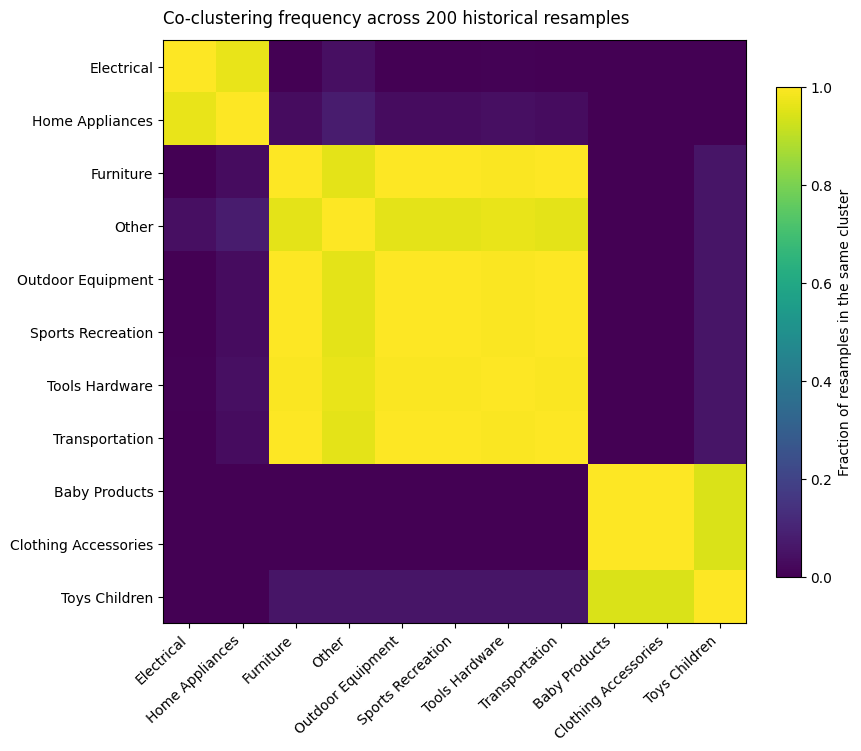

In [2]:
N_CLUSTERS = 3
N_RESAMPLES = 200
RESAMPLE_SEED = 2026

# 一行对应一个已识别失效的历史组合，六列可同时为 1。
mode_matrices = [
    np.array([[mode in case["modes"] for mode in FAILURE_MODES]
              for case in history_by_category[category] if case["modes"]], dtype=bool)
    for category in categories
]
known_modes = set(FAILURE_MODES)
if any(case["modes"] - known_modes for case in history):
    raise ValueError("交接数据含六类词典之外的失效标签，请核对与 B 的输入口径。")
if any(len(matrix) == 0 for matrix in mode_matrices):
    raise ValueError("至少一个大类没有可供重抽样的失效标签。")
profiles = np.stack([matrix.mean(axis=0) for matrix in mode_matrices])
print(f"{sum(len(matrix) for matrix in mode_matrices):,}/{len(history):,} 个建模组合识别到失效。")


def cluster_categories(values):
    return KMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=50,
                  random_state=42).fit_predict(values)


def same_cluster(labels):
    return labels[:, None] == labels[None, :]


rng = np.random.default_rng(RESAMPLE_SEED)
co_cluster_counts = np.zeros((len(categories), len(categories)), dtype=int)
matching_rounds = 0
with threadpool_limits(limits=1):
    b_clusters = cluster_categories(profiles)
    b_membership = same_cluster(b_clusters)
    for _ in range(N_RESAMPLES):
        sampled_profiles = np.stack([
            matrix[rng.integers(len(matrix), size=len(matrix))].mean(axis=0)
            for matrix in mode_matrices
        ])
        membership = same_cluster(cluster_categories(sampled_profiles))
        co_cluster_counts += membership
        matching_rounds += int(np.array_equal(membership, b_membership))

consensus = co_cluster_counts / N_RESAMPLES
assert np.array_equal(co_cluster_counts, co_cluster_counts.T)
assert np.all(co_cluster_counts.diagonal() == N_RESAMPLES)
assert np.all((consensus >= 0) & (consensus <= 1))

pair_rows, pair_columns = np.triu_indices(len(categories), k=1)
within_b = b_membership[pair_rows, pair_columns]
pair_frequencies = consensus[pair_rows, pair_columns]
print(f"{matching_rounds}/{N_RESAMPLES} 轮复现了 B 的全部同簇关系。")
for title, values in (("B 同簇类别对", pair_frequencies[within_b]),
                      ("B 跨簇类别对", pair_frequencies[~within_b])):
    print(f"{title}（{len(values)} 对）同簇频率：均值 {values.mean():.1%}，"
          f"范围 {values.min():.1%}–{values.max():.1%}。")

# 把 B 的同簇类别放在相邻位置，便于看重抽样中是否出现跨簇关系。
order = np.argsort(b_clusters, kind="stable")
axis_names = [categories[i].replace("_", " ").title() for i in order]
fig, ax = plt.subplots(figsize=(8.6, 7.4), layout="constrained")
heatmap = ax.imshow(consensus[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(categories)), axis_names, rotation=43, ha="right")
ax.set_yticks(range(len(categories)), axis_names)
ax.set_title(f"Co-clustering frequency across {N_RESAMPLES} historical resamples", loc="left", pad=12)
fig.colorbar(heatmap, ax=ax, label="Fraction of resamples in the same cluster", shrink=0.84)
plt.show()

## 2　保持同样的危险打分和回测规则

A 使用本类全部历史组合上的危险比例。B 对同簇其他类等权借鉴，C 则把与目标类同簇的频率归一化为类别权重。有 100% 同簇与 20% 同簇的两个参考类时，两者在外部部分的权重分别为 5/6 和 1/6。本类仍占总得分的 50%，其他类合计占 50%。若没有任何可参考类，沿用本类比例。

回测标签统一为 `hazard_classification`。主对照固定每类提示两项，另复用 A、B 已确定的 0.15 门槛，达标不足两项时补足两项。得分并列时按建模期总体危险计数和标签名排序。用 micro-F1 评价所有危险标签，用「命中组合数」统计至少提示到一个已有危险标签的组合。

In [3]:
EXTERNAL_SHARE = Fraction(1, 2)
THRESHOLD = Fraction(15, 100)

hazards_by_id = defaultdict(set)
for case in history:
    hazards_by_id[case["id"]].update(case["hazards"])
global_counts = Counter(hazard for labels in hazards_by_id.values() for hazard in labels)
own_rates = {
    category: {hazard: Fraction(sum(hazard in case["hazards"] for case in records), len(records))
               for hazard in hazards}
    for category, records in history_by_category.items()
}


def blend_hazard_scores(weights):
    scores = {}
    for category, row_weights in zip(categories, weights):
        peers = {peer: int(weight) for peer, weight in zip(categories, row_weights)
                 if peer != category and weight > 0}
        weight_total = sum(peers.values())
        if not weight_total:
            scores[category] = own_rates[category]
            continue
        scores[category] = {
            hazard: (1 - EXTERNAL_SHARE) * own_rates[category][hazard]
            + EXTERNAL_SHARE * sum(weight * own_rates[peer][hazard] for peer, weight in peers.items()) / weight_total
            for hazard in hazards
        }
    return scores


def choose_hazards(scores, threshold):
    ranked = sorted(scores, key=lambda hazard: (-scores[hazard], -global_counts[hazard], hazard))
    qualified = [hazard for hazard in ranked if threshold is not None and scores[hazard] >= threshold]
    return qualified if len(qualified) >= 2 else ranked[:2]


methods = {"A 本类历史": own_rates,
           "B K-means": blend_hazard_scores(b_membership),
           "C 共识频率加权": blend_hazard_scores(co_cluster_counts)}
protocols = {"固定两项": None, "0.15 门槛，至少两项": THRESHOLD}
predictions = {
    protocol: {
        method: {category: choose_hazards(scores, threshold) for category, scores in category_scores.items()}
        for method, category_scores in methods.items()
    }
    for protocol, threshold in protocols.items()
}

In [4]:
def evaluate(predicted_by_category):
    matches, prompts = [], 0
    true_positives, false_positives, false_negatives = Counter(), Counter(), Counter()
    for case in evaluation:
        predicted = set(predicted_by_category[case["category"]])
        actual = case["hazards"]
        tp = predicted & actual
        matches.append(bool(tp))
        prompts += len(predicted)
        true_positives.update(tp)
        false_positives.update(predicted - actual)
        false_negatives.update(actual - predicted)

    tp, fp, fn = (sum(counts.values()) for counts in
                  (true_positives, false_positives, false_negatives))
    metrics = {
        "命中组合": sum(matches), "组合数": len(matches), "平均提示数": prompts / len(matches),
        "精确率": tp / (tp + fp), "标签召回率": tp / (tp + fn),
        "micro-F1": 2 * tp / (2 * tp + fp + fn),
    }
    return metrics, matches, true_positives


summary, paired, changed, evaluation_results = [], [], [], {}
for protocol, method_lists in predictions.items():
    evaluation_results[protocol] = results = {
        method: evaluate(by_category) for method, by_category in method_lists.items()
    }
    for method, (metrics, _, _) in results.items():
        summary.append({"回测口径": protocol, "方法": method, **metrics})

    _, b_matches, _ = results["B K-means"]
    _, c_matches, _ = results["C 共识频率加权"]
    b_lists, c_lists = method_lists["B K-means"], method_lists["C 共识频率加权"]
    changed_categories = [category for category in categories if set(b_lists[category]) != set(c_lists[category])]
    paired.append({
        "回测口径": protocol, "清单变动的大类数": len(changed_categories),
        "C 新增命中组合": sum(not b_hit and c_hit for b_hit, c_hit in zip(b_matches, c_matches)),
        "C 漏掉 B 命中的组合": sum(b_hit and not c_hit for b_hit, c_hit in zip(b_matches, c_matches)),
    })
    for category in changed_categories:
        changed.append({"回测口径": protocol, "大类": CATEGORY_NAMES[category],
                        "B 提示": "、".join(HAZARD_NAMES.get(h, h) for h in b_lists[category]),
                        "C 提示": "、".join(HAZARD_NAMES.get(h, h) for h in c_lists[category])})

display(pd.DataFrame(summary).round(3))
display(pd.DataFrame(paired))
if changed:
    display(pd.DataFrame(changed))
else:
    print("两种回测口径下，C 与 B 的 11 个大类的危险清单集合均相同。")

label_counts = Counter(hazard for case in evaluation for hazard in case["hazards"])
label_rows = []
for hazard in hazards:
    result = {"危险": HAZARD_NAMES.get(hazard, hazard), "回测标签数": label_counts[hazard]}
    for method, (_, _, true_positives) in evaluation_results["固定两项"].items():
        result[method] = true_positives[hazard] / label_counts[hazard]
    label_rows.append(result)
print("固定两项时的逐危险标签召回率")
display(pd.DataFrame(label_rows).round(3))

两种回测口径下，C 与 B 的 11 个大类的危险清单集合均相同。
固定两项时的逐危险标签召回率


,回测口径,方法,命中组合,组合数,平均提示数,精确率,标签召回率,micro-F1
0,固定两项,A 本类历史,973,1491,2.000,0.327,0.651,0.435
1,固定两项,B K-means,854,1491,2.000,0.287,0.572,0.382
2,固定两项,C 共识频率加权,854,1491,2.000,0.287,0.572,0.382
3,0.15 门槛，至少两项,A 本类历史,1049,1491,2.190,0.322,0.703,0.442
4,0.15 门槛，至少两项,B K-means,921,1491,2.281,0.272,0.618,0.377
5,0.15 门槛，至少两项,C 共识频率加权,921,1491,2.281,0.272,0.618,0.377


,回测口径,清单变动的大类数,C 新增命中组合,C 漏掉 B 命中的组合
0,固定两项,0,0,0
1,0.15 门槛，至少两项,0,0,0


,危险,回测标签数,A 本类历史,B K-means,C 共识频率加权
0,灼伤,129,0.659,0.419,0.419
1,窒息或噎塞,143,0.930,0.930,0.930
2,碰撞事故,127,0.764,0.764,0.764
3,割伤,87,0.299,0.299,0.299
4,跌落,220,0.841,0.855,0.855
5,火灾,347,0.784,0.784,0.784
6,热相关爆炸,7,0.000,0.000,0.000
7,撞击伤害,113,0.230,0.230,0.230
8,其他危险,84,0.000,0.000,0.000
9,中毒,200,0.750,0.295,0.295


In [5]:
example_category = "SPORTS_RECREATION"
example_hazard = "FIRE"
print("运动休闲类的火灾得分")
for method, scores in methods.items():
    print(f"{method}  {float(scores[example_category][example_hazard]):.2%}")

运动休闲类的火灾得分
A 本类历史  3.18%
B K-means  16.12%
C 共识频率加权  16.01%


## 3　本次回测结论

- **C 与 B 持平。** 固定两项时，两者都命中 854/1,491，micro-F1 均为 0.382。沿用 0.15 门槛时，两者都命中 921/1,491，micro-F1 均为 0.377。两种口径下，11 个大类的提示标签集合都相同，新增命中和漏掉的命中均为 0。
- **原分组对这次重抽样较稳定。** 200 轮中有 174 轮完整复现 B 的同簇关系。B 的同簇类别对在 94.5%–100% 的轮次仍同簇，B 的跨簇类别对至多在 7.5% 的轮次同簇。C 调整了一些危险得分，例如将运动休闲类的火灾得分从 16.12% 调为 16.01%，两项得分均达到 15% 门槛，清单因此相同。
- **设计复查仍以 A 为主要危险清单。** 固定两项时，A 命中 973/1,491，micro-F1 为 0.435。C 的共识矩阵补充了对 B 分组稳定性的证据。这个结论适用于现有六类失效表示、时间切分和 50% 外部权重。历史组合中约 52.9% 识别出失效，其他记录仍计入危险比例。